# Setup

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
%matplotlib ipympl
from Util.util import load_keypoints_and_labels,angle_between_vectors,get_segment_borders
from Util.pulltest_util import get_axis_velocity, fill_short_runs, get_trunk_vectors
from scipy.signal import find_peaks

In [2]:
recording_name = "tug2"
filename_stereo = os.path.join("data", recording_name, recording_name + "_stereo.npz")
filename_qualisys = os.path.join("data", recording_name, recording_name + "_qualisys.npz")
stereo_keypoints, stereo_labels = load_keypoints_and_labels(filename=filename_stereo)
qualisys_keypoints, qualisys_labels = load_keypoints_and_labels(filename=filename_qualisys)

fps = 100
q_cut_1 = 900
s_cut_1 = 1000
q_cut_2 = q_cut_1 + len(stereo_keypoints) - s_cut_1 #TODO: this only works if the qualisys recoridng is longer than the stereo
BASELINE_DURATION = 3 # seconds
baseline_end = BASELINE_DURATION * fps


qualisys_keypoints = qualisys_keypoints[q_cut_1:q_cut_2,:,:]
stereo_keypoints = stereo_keypoints[s_cut_1:,:,:]

loaded data from: data\tug2\tug2_stereo.npz with keys: ['labels', 'keypoints']
loaded data from: data\tug2\tug2_qualisys.npz with keys: ['labels', 'keypoints']


In [3]:
def get_hips_down_mask(keypoints: np.ndarray, labels: list, baseline_end: float, threshold: float):
    """
    Creates a mask indicating when the hips are in a sitting position (based on sitting baseline) using vertical coordinate

    Args:
        keypoints: keypoint data (n_frames, n_kpts, n_dims)
        labels: labels for the keypoints
        baseline_end: end of the baseline period (in samples)
        threshold: fraction of total movement above which it no longer counts as sitting down

    Returns:
        hips_down_mask: mask indicating if the hips are in sitting position
        hip_vertical_normalized: vertical  hip position normalized to [0, max dispacement]
    """
    hip_vertical_position = keypoints[:, labels.index("mid_hip"), 2]
    hip_vertical_position_baseline = np.nanmean(hip_vertical_position[:baseline_end])
    hip_vertical_baseline_diff = hip_vertical_position - hip_vertical_position_baseline
    hip_vertical_normalized = hip_vertical_baseline_diff / np.nanpercentile(
        hip_vertical_baseline_diff, 99
    )
    hips_down_mask = hip_vertical_normalized < threshold
    return hips_down_mask, hip_vertical_normalized


def get_trunk_angle_and_movement_mask(
    keypoints: np.ndarray,
    labels: list,
    baseline_end: float,
    threshold: float,
    min_lean_time: float,
    fps: float,
):
    """
    Calculates the angle of the trunk vectors (mid_hip -> mid_shoulder) compared to their baseline mean (sitting).
    Also creates a movement mask indicating when the lean angle is less than threshold.

    Args:
        keypoints: keypoint data (n_frames, n_kpts, n_dims)
        labels: labels for the keypoints
        baseline_end: end of the baseline period (in samples)
        threshold: limit (in degrees) above which leaning/movement is detected
        min_lean_time: duration of time (in seconds) below which leaning/movement is considered noise
    """
    trunk_vectors = get_trunk_vectors(keypoints, labels)
    trunk_vector_baseline = np.nanmean(trunk_vectors[:baseline_end], axis=0)
    trunk_angles = np.array(
        [
            angle_between_vectors(trunk_vector, trunk_vector_baseline)
            for trunk_vector in trunk_vectors
        ]
    )
    trunk_angle_baseline = np.nanmean(trunk_angles[:baseline_end])
    leaning_mask = (trunk_angles - trunk_angle_baseline) < threshold
    leaning_mask = fill_short_runs(leaning_mask, value=0, min_length=min_lean_time * fps).astype(
        bool
    )
    return trunk_angles, leaning_mask

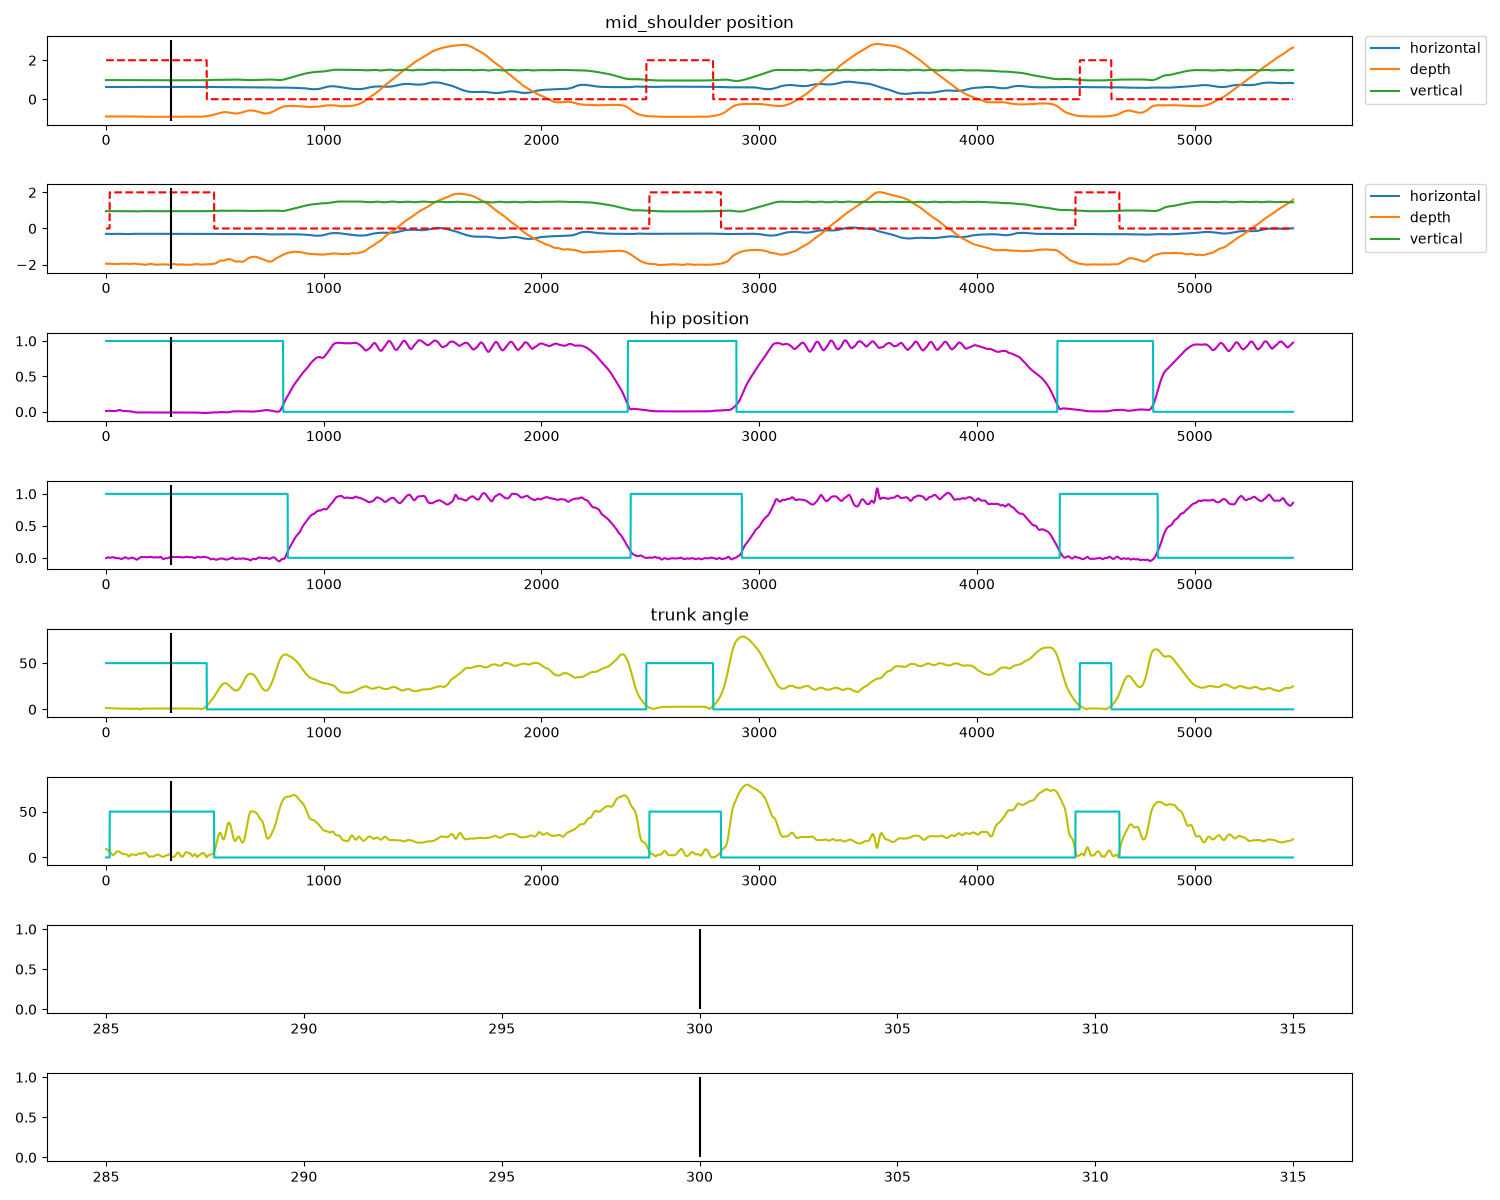

In [ ]:
# qualisys_shoulder_vector = np.gradient(qualisys_keypoints[:,qualisys_labels.index('left_shoulder'),0]-qualisys_keypoints[:,qualisys_labels.index('right_shoulder'),0], axis=0)
# stereo_shoulder_vector = np.gradient(stereo_keypoints[:,stereo_labels.index('left_shoulder'),0]-stereo_keypoints[:,stereo_labels.index('right_shoulder'),0], axis=0)

# hip position
HIP_POSITION_THR = 0.1  # fraction (normalized)
qualisys_hips_down, qualisys_hip_normalized = get_hips_down_mask(
    qualisys_keypoints, qualisys_labels, baseline_end, HIP_POSITION_THR
)
stereo_hips_down, stereo_hip_normalized = get_hips_down_mask(
    stereo_keypoints, stereo_labels, baseline_end, HIP_POSITION_THR
)

# lean angle
TRUNK_ANGLE_THR = 3  # degrees
MIN_LEAN_TIME = 1
qualisys_trunk_angles, qualisys_leaning_mask = get_trunk_angle_and_movement_mask(
    qualisys_keypoints, qualisys_labels, baseline_end, TRUNK_ANGLE_THR, MIN_LEAN_TIME, 100
)
stereo_trunk_angles, stereo_leaning_mask = get_trunk_angle_and_movement_mask(
    stereo_keypoints, stereo_labels, baseline_end, TRUNK_ANGLE_THR, MIN_LEAN_TIME, 100
)


qualisys_sit_mask = qualisys_hips_down & qualisys_leaning_mask
stereo_sit_mask = stereo_hips_down & stereo_leaning_mask

plt.close("all")
fig, axs = plt.subplots(8, 1, figsize=(15, 12))

axs[0].set_title("mid_shoulder position")
axs[0].plot(qualisys_keypoints[:, qualisys_labels.index("mid_shoulder"), :],label=["horizontal", "depth", "vertical"],)
axs[0].plot(qualisys_sit_mask * 2, "r--")
axs[0].legend(loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)
axs[1].plot(stereo_keypoints[:, stereo_labels.index("mid_shoulder"), :],label=["horizontal", "depth", "vertical"],)
axs[1].plot(stereo_sit_mask * 2, "r--")
axs[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)

axs[2].set_title("hip position")
axs[2].plot(qualisys_hip_normalized, "m")
axs[2].plot(qualisys_hips_down, "c")
axs[3].plot(stereo_hip_normalized, "m")
axs[3].plot(stereo_hips_down, "c")

axs[4].set_title("trunk angle")
axs[4].plot(qualisys_trunk_angles, "y")
axs[4].plot(qualisys_leaning_mask * 50, "c")
axs[5].plot(stereo_trunk_angles, "y")
axs[5].plot(stereo_leaning_mask * 50, "c")


for ax in axs:
    y_min, y_max = ax.get_ylim()
    ax.vlines(baseline_end, y_min, y_max, "k")
    # for segment_border in qualisys_baseline_segments:

    #     ax.vlines(segment_border, y_min, y_max)
    # ax.vlines(5280, y_min, y_max)

plt.tight_layout()